In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta.

In [4]:
pregunta_1 = "1. Dibuje el grafo Roy y calcule sobre él, actividad a actividad y en orden topológico, el inicio y el fin más tempranos: el inicio más temprano es el mayor de los fines más tempranos de las predecesoras.  "
pregunta_2 = "2. Calcule del mismo modo, de atrás hacia delante, los fines e inicios más tardíos.  "
pregunta_3 = "3. Para cada actividad con varias predecesoras indique cuál de ellas fija su inicio más temprano (la *predecesora dominante*). En particular, ¿qué predecesora de H manda?  "
pregunta_4 = "4. Si se quisiera adelantar el inicio de H un día, ¿qué actividad habría que acortar? ¿Serviría de algo acortar sus otras predecesoras?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo Roy y calcule sobre él, actividad a actividad y en orden topológico, el inicio y el fin más tempranos: el inicio más temprano es el mayor de los fines más tempranos de las predecesoras.  

2. Calcule del mismo modo, de atrás hacia delante, los fines e inicios más tardíos.  

3. Para cada actividad con varias predecesoras indique cuál de ellas fija su inicio más temprano (la *predecesora dominante*). En particular, ¿qué predecesora de H manda?  

4. Si se quisiera adelantar el inicio de H un día, ¿qué actividad habría que acortar? ¿Serviría de algo acortar sus otras predecesoras?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 3       ),
    ('B'     , '---'      , 2       ),
    ('C'     , 'A,B'      , 7       ),
    ('D'     , 'B'        , 6       ),
    ('E'     , 'B'        , 7       ),
    ('F'     , 'C,D'      , 4       ),
    ('G'     , 'C'        , 7       ),
    ('H'     , 'E,F,G'    , 3       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,3
B,---,2
C,"A,B",7
D,B,6
E,B,7
F,"C,D",4
G,C,7
H,"E,F,G",3


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
predecesoras = prelaciones.immediate_predecessor
sucesoras = {a: sorted(s for s, ps in predecesoras.items() if a in ps) for a in datos_proyecto.index}
duracion = datos_proyecto['duration']

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el grafo Roy y calcule sobre él, actividad a actividad y en orden topológico, el inicio y el fin más tempranos: el inicio más temprano es el mayor de los fines más tempranos de las predecesoras.  

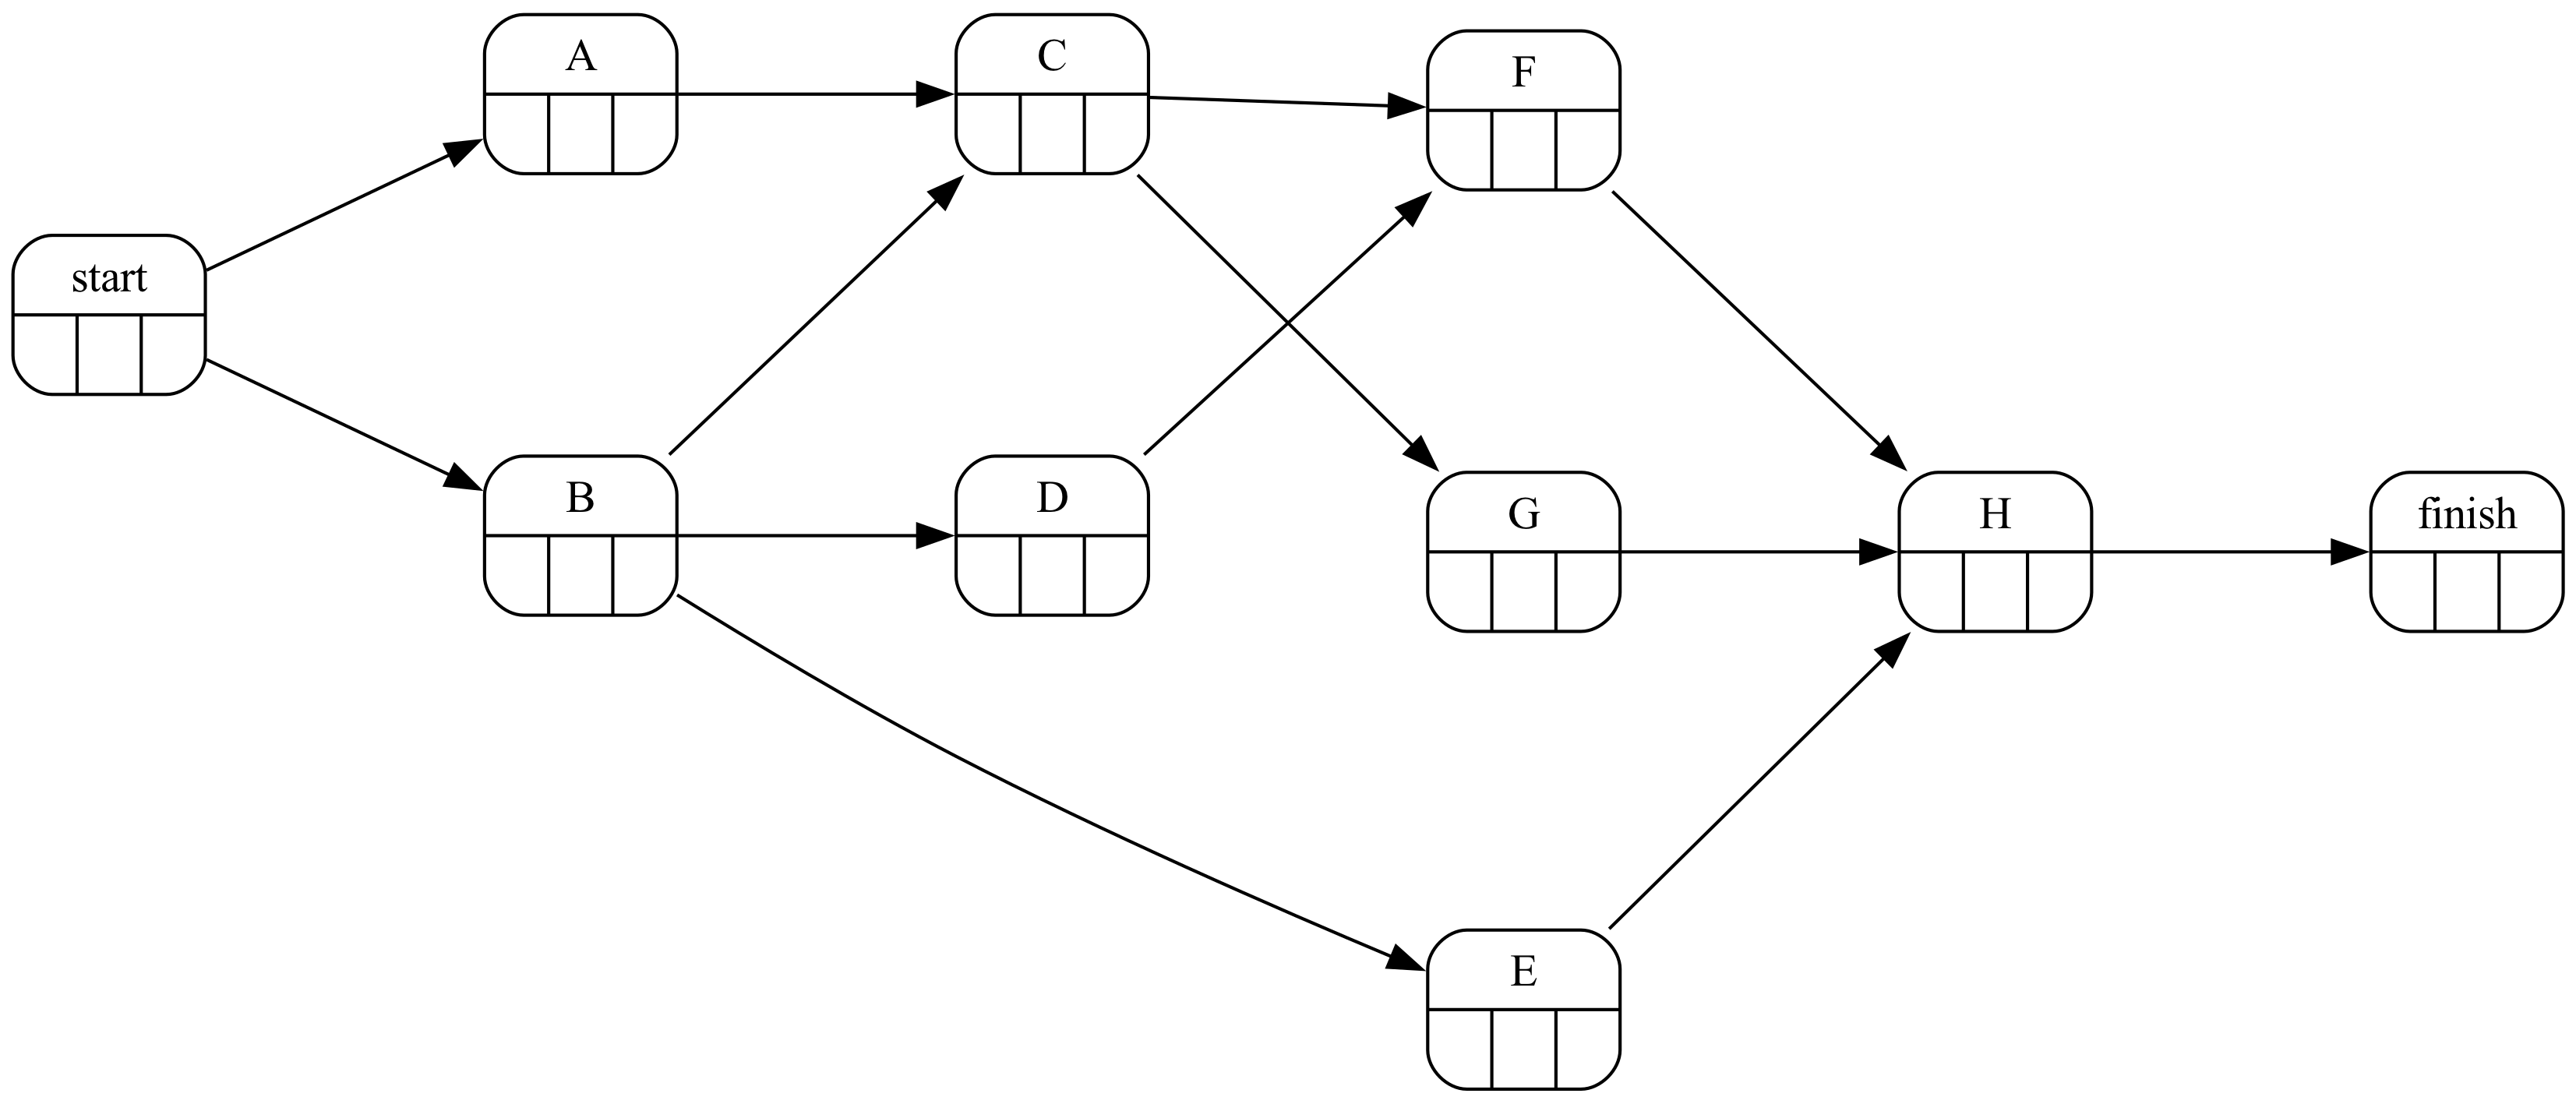

In [8]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-roy
proyecto.roy(ranksep=1.2, nodesep=1.2)

Recorriendo las actividades en un orden en que cada una aparece después de sus predecesoras (orden topológico):

In [9]:
G = nx.DiGraph([(p, a) for a, ps in predecesoras.items() for p in ps])
G.add_nodes_from(datos_proyecto.index)
orden = list(nx.topological_sort(G))
ES, EF, filas = {}, {}, []
for a in orden:
    ps = sorted(predecesoras[a])
    ES[a] = max((EF[p] for p in ps), default=0)
    EF[a] = ES[a] + int(duracion[a])
    filas.append({'actividad': a, 'predecesoras (EF)': ', '.join(f'{p} ({EF[p]})' for p in ps) or '—',
                  'ES = máx': ES[a], 'duración': int(duracion[a]), 'EF = ES + d': EF[a]})
pd.DataFrame(filas).set_index('actividad')

,predecesoras (EF),ES = máx,duración,EF = ES + d
actividad,,,,
A,—,0,3,3
B,—,0,2,2
C,"A (3), B (2)",3,7,10
D,B (2),2,6,8
E,B (2),2,7,9
G,C (10),10,7,17
F,"C (10), D (8)",10,4,14
H,"E (9), F (14), G (17)",17,3,20


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Calcule del mismo modo, de atrás hacia delante, los fines e inicios más tardíos.  

In [11]:
duracion_proyecto = max(EF.values())
LS, LF, filas = {}, {}, []
for a in reversed(orden):
    ss = sucesoras[a]
    LF[a] = min((LS[s] for s in ss), default=duracion_proyecto)
    LS[a] = LF[a] - int(duracion[a])
    filas.append({'actividad': a, 'sucesoras (LS)': ', '.join(f'{s} ({LS[s]})' for s in ss) or '—',
                  'LF = mín': LF[a], 'duración': int(duracion[a]), 'LS = LF − d': LS[a]})
pd.DataFrame(filas).set_index('actividad')

,sucesoras (LS),LF = mín,duración,LS = LF − d
actividad,,,,
H,—,20,3,17
F,H (17),17,4,13
G,H (17),17,7,10
E,H (17),17,7,10
D,F (13),13,6,7
C,"F (13), G (10)",10,7,3
B,"C (3), D (7), E (10)",3,2,1
A,C (3),3,3,0


In [12]:
calendario = proyecto.calendar(duracion)
coincide = all(calendario.loc[a, 'inicio_mas_temprano'] == ES[a] and calendario.loc[a, 'inicio_mas_tardio'] == LS[a] for a in orden)
Markdown(f'La duración del proyecto es {duracion_proyecto} días. El cálculo coincide con el de la librería: {coincide}.')

La duración del proyecto es 20 días. El cálculo coincide con el de la librería: True.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Para cada actividad con varias predecesoras indique cuál de ellas fija su inicio más temprano (la *predecesora dominante*). En particular, ¿qué predecesora de H manda?  

In [14]:
dominantes = {}
for a in datos_proyecto.index:
    ps = sorted(predecesoras[a])
    if len(ps) >= 2:
        maximo = max(EF[p] for p in ps)
        dominantes[a] = ', '.join(p for p in ps if EF[p] == maximo)
pd.Series(dominantes).to_frame('predecesora dominante')

,predecesora dominante
C,A
F,C
H,G


La predecesora dominante de H es G: su fin más temprano es el mayor de entre las predecesoras y por tanto el que fija el inicio de H. Las demás predecesoras terminan antes y tienen margen (holgura libre) respecto a H.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Si se quisiera adelantar el inicio de H un día, ¿qué actividad habría que acortar? ¿Serviría de algo acortar sus otras predecesoras?  

In [16]:
objetivo, dominante = 'H', 'G'
otras = [p for p in sorted(predecesoras[objetivo]) if p != dominante]
margen = {p: EF[dominante] - EF[p] for p in otras}
d2 = duracion.copy(); d2[dominante] -= 1
ES_nuevo = int(proyecto.calendar(d2).loc[objetivo, 'inicio_mas_temprano'])
Markdown(f'''Para adelantar {objetivo} hay que acortar {dominante} (o alguna de sus antecesoras en la cadena que la hace llegar la última): acortándola un día, {objetivo} empieza en {ES_nuevo} en vez de {ES[objetivo]}. Acortar {", ".join(otras)} no sirve: terminan {", ".join(f"{p} {m} día(s)" for p, m in margen.items())} antes que {dominante} y su holgura sólo aumentaría. Sólo cuando {dominante} se acorte tanto que otra predecesora pase a ser la última cambiará la dominante.''')

Para adelantar H hay que acortar G (o alguna de sus antecesoras en la cadena que la hace llegar la última): acortándola un día, H empieza en 16 en vez de 17. Acortar E, F no sirve: terminan E 8 día(s), F 3 día(s) antes que G y su holgura sólo aumentaría. Sólo cuando G se acorte tanto que otra predecesora pase a ser la última cambiará la dominante.